# Day 19: Systematic Prompt Engineering
**Task:** Question answering over the Veridia Labs knowledge base (same fictional company as Day 15).

**Plan:** baseline prompt -> 5 techniques (role, format, chain-of-thought, few-shot, negative constraints) on the same 10 inputs -> version dictionary -> best technique + hypothesis -> grounding prompt for RAG -> 5 out-of-context tests.

**Model:** local Qwen2.5-1.5B-Instruct (no OpenAI key needed). Use a **T4 GPU** runtime.

## Step 0: Install and load the model
We use the same local stack as Days 15-18 so results are comparable. Greedy decoding (`do_sample=False`) makes every run deterministic, so score differences come from the prompt only, not randomness.

In [1]:
!pip -q install transformers sentence-transformers accelerate

In [2]:
import torch, json, re, numpy as np
from transformers import AutoTokenizer, AutoModelForCausalLM

MODEL = "Qwen/Qwen2.5-1.5B-Instruct"
tok = AutoTokenizer.from_pretrained(MODEL)
model = AutoModelForCausalLM.from_pretrained(MODEL, torch_dtype=torch.float16, device_map="auto")

def chat(messages, max_new_tokens=120):
    text = tok.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    inputs = tok(text, return_tensors="pt").to(model.device)
    with torch.no_grad():
        out = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
    return tok.decode(out[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True).strip()

print(chat([{"role": "user", "content": "Say hello in 5 words."}]))

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Hello there! How can I assist you today?


## Step 1: Task, knowledge base and 10 test inputs
The model cannot know Veridia Labs facts, so every answer is checkable. We retrieve the top-3 chunks (MiniLM + cosine similarity) as context, exactly like a RAG pipeline.

Each test input has `facts`: a list of required facts, each fact a list of acceptable spellings. This drives the scoring below.

In [3]:
from sentence_transformers import SentenceTransformer

KB = [
 "Veridia Labs was founded in 2019 in Pune, India by Dr. Meera Kulkarni.",
 "Veridia's flagship product is Lumen, a document analysis platform launched in March 2021.",
 "The Lumen Basic plan costs $29 per month and the Lumen Pro plan costs $99 per month.",
 "Monthly plans can be refunded within 14 days of purchase. Annual plans can be refunded within 30 days of purchase.",
 "Customer support is available from 9am to 6pm IST, Monday to Friday, at support@veridia.example.",
 "Veridia Labs has 240 employees in total: 150 in Pune, 40 in Anantnag and 50 in Berlin.",
 "Lumen supports PDF, DOCX and CSV files up to 50 MB each.",
 "Customer data is stored on servers in the Frankfurt region and encrypted with AES-256.",
 "The Lumen API allows 100 requests per minute on the Pro plan. The Basic plan has no API access.",
 "Veridia Labs holds its annual company retreat every October in Gulmarg.",
]

EVAL = [
 {"q": "Who founded Veridia Labs and in which city?",                     "facts": [["kulkarni"], ["pune"]]},
 {"q": "When was Lumen launched?",                                         "facts": [["march"], ["2021"]]},
 {"q": "How much more per month does Pro cost than Basic?",                "facts": [["70"]]},
 {"q": "Can I get a refund on an annual plan 20 days after buying it?",    "facts": [["yes"], ["30"]]},
 {"q": "When is customer support available?",                              "facts": [["9"], ["6"], ["monday"], ["friday"]]},
 {"q": "How many employees does Veridia Labs have in total?",              "facts": [["240"]]},
 {"q": "Which file types does Lumen support?",                             "facts": [["pdf"], ["docx"], ["csv"]]},
 {"q": "Where is customer data stored and how is it encrypted?",           "facts": [["frankfurt"], ["aes"]]},
 {"q": "Does the Basic plan include API access?",                          "facts": [["no", "not", "n't"]]},
 {"q": "In which month and where is the annual company retreat?",          "facts": [["october"], ["gulmarg"]]},
]

embedder = SentenceTransformer("all-MiniLM-L6-v2")
kb_vecs = embedder.encode(KB, normalize_embeddings=True)

def retrieve(query, k=3):
    qv = embedder.encode([query], normalize_embeddings=True)[0]
    idx = np.argsort(-(kb_vecs @ qv))[:k]
    return "\n".join(f"- {KB[i]}" for i in idx)

for item in EVAL:
    item["context"] = retrieve(item["q"])
print(EVAL[2]["context"])

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (4 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

- The Lumen Basic plan costs $29 per month and the Lumen Pro plan costs $99 per month.
- The Lumen API allows 100 requests per minute on the Pro plan. The Basic plan has no API access.
- Veridia Labs has 240 employees in total: 150 in Pune, 40 in Anantnag and 50 in Berlin.


## Step 2: Scoring rubric (defined BEFORE running anything)
- **Accuracy (1-5):** `1 + round(4 * fraction_of_required_facts_found)` in the final answer. All facts present = 5, none = 1.
- **Format consistency (1-5):** the target format is *one short sentence starting with `Answer:`*. Start at 1, then +2 if a final line starts with `Answer:`, +1 if the final answer is a single sentence, +1 if it is 25 words or fewer. Reasoning lines before the final `Answer:` line are allowed.

**Why define it first?** If you write the rubric after seeing outputs, you unconsciously bend it to favour what you liked. Fixed rules make the comparison fair.

**Honest limitation:** this is an automatic keyword scorer, so it is approximate. Read the printed outputs and, where the scorer is wrong, put your own scores in `MANUAL` (`{(version_name, input_index): (accuracy, format)}`).

In [4]:
MANUAL = {}   # e.g. {("v0_baseline", 4): (3, 2)}

def split_answer(text):
    lines = [l.strip() for l in text.strip().splitlines() if l.strip()]
    for l in reversed(lines):
        if l.lower().startswith("answer:"):
            return l[len("answer:"):].strip(), True
    return text.strip(), False

def sentence_count(s):
    return max(1, len(re.findall(r"[.!?](?:\s|$)", s)))

def score_accuracy(item, text):
    ans, _ = split_answer(text)
    a = ans.lower()
    hits = sum(any(alt in a for alt in alts) for alts in item["facts"])
    return 1 + round(4 * hits / len(item["facts"]))

def score_format(text):
    ans, has_prefix = split_answer(text)
    s = 1
    if has_prefix: s += 2
    if sentence_count(ans) == 1: s += 1
    if len(ans.split()) <= 25: s += 1
    return s

## Step 3: Prompt builder
One function builds every prompt version from on/off switches (`role`, `fmt`, `cot`, `fewshot`, `neg`). With one builder, the *only* thing that differs between runs is the switches, which is what makes this a controlled experiment.

In [5]:
FEWSHOT = '''Here are two examples of the expected style:

Context: Orbit Cafe opens at 8am and closes at 10pm daily.
Question: When does Orbit Cafe close?
Answer: Orbit Cafe closes at 10pm daily.

Context: Orbit Cafe sells coffee for $3 and tea for $2.
Question: How much does tea cost?
Answer: Tea costs $2.

Now answer the real question.
'''

def build_messages(cfg, ctx, q):
    system = ("You are a precise customer-support assistant for Veridia Labs."
              if cfg.get("role") else "You are a helpful assistant.")
    user = ""
    if cfg.get("fewshot"):
        user += FEWSHOT + "\n"
    user += f"Context:\n{ctx}\n\nQuestion: {q}\n\nAnswer the question using the context."
    if cfg.get("fmt"):
        user += "\nFormat: reply with one short sentence that starts with 'Answer:'."
    if cfg.get("neg"):
        user += "\nDo not guess. Do not use outside knowledge. Do not add extra explanation or mention these instructions."
    if cfg.get("cot"):
        user += "\nThink step by step first, then put your final answer on the last line."
    return [{"role": "system", "content": system}, {"role": "user", "content": user}]

def run_version(name, cfg):
    rows = []
    for i, item in enumerate(EVAL):
        out = chat(build_messages(cfg, item["context"], item["q"]),
                   max_new_tokens=220 if cfg.get("cot") else 120)
        acc, fmt = MANUAL.get((name, i), (score_accuracy(item, out), score_format(out)))
        rows.append({"i": i, "q": item["q"], "output": out, "acc": acc, "fmt": fmt})
    avg_acc = float(np.mean([r["acc"] for r in rows]))
    avg_fmt = float(np.mean([r["fmt"] for r in rows]))
    return {"name": name, "cfg": cfg, "rows": rows, "avg_acc": avg_acc,
            "avg_fmt": avg_fmt, "avg": (avg_acc + avg_fmt) / 2}

def show(res):
    print(f"== {res['name']} | accuracy {res['avg_acc']:.2f} | format {res['avg_fmt']:.2f} | overall {res['avg']:.2f}")
    for r in res["rows"]:
        print(f"[{r['i']}] acc={r['acc']} fmt={r['fmt']} | {r['q']}\n     -> {r['output'][:200]!r}")

## Step 4: Baseline
The plain prompt. Every technique must beat this number to count as an improvement.

In [6]:
RESULTS = {}
RESULTS["v0_baseline"] = run_version("v0_baseline", {})
show(RESULTS["v0_baseline"])

== v0_baseline | accuracy 4.60 | format 2.40 | overall 3.50
[0] acc=5 fmt=2 | Who founded Veridia Labs and in which city?
     -> 'Veridia Labs was founded in 2019 in Pune, India by Dr. Meera Kulkarni.'
[1] acc=5 fmt=3 | When was Lumen launched?
     -> 'Lumen was launched in March 2021.'
[2] acc=1 fmt=1 | How much more per month does Pro cost than Basic?
     -> 'To determine how much more per month the Lumen Pro plan costs compared to the Lumen Basic plan:\n\n1. Identify the monthly cost of each plan:\n   - Lumen Basic plan: $29 per month\n   - Lumen Pro plan: $9'
[3] acc=5 fmt=1 | Can I get a refund on an annual plan 20 days after buying it?
     -> 'Yes, you can get a refund on an annual plan 20 days after purchasing it. According to the provided context, annual plans can be refunded within 30 days of purchase. Since 20 days is less than 30 days,'
[4] acc=5 fmt=3 | When is customer support available?
     -> 'Customer support is available from 9am to 6pm IST, Monday to Friday, at s

## Step 5: Each technique on its own (isolated)
Each technique is added to the baseline **alone**. This answers "which single technique helps most?" without mixing effects.

In [7]:
ISOLATED = {
    "role":     {"role": True},
    "format":   {"fmt": True},
    "cot":      {"cot": True},
    "fewshot":  {"fewshot": True},
    "negative": {"neg": True},
}
ISO = {}
for tech, cfg in ISOLATED.items():
    ISO[tech] = run_version(f"iso_{tech}", cfg)
    print(f"{tech:10s} acc={ISO[tech]['avg_acc']:.2f}  fmt={ISO[tech]['avg_fmt']:.2f}  overall={ISO[tech]['avg']:.2f}")
print(f"{'baseline':10s} acc={RESULTS['v0_baseline']['avg_acc']:.2f}  fmt={RESULTS['v0_baseline']['avg_fmt']:.2f}  overall={RESULTS['v0_baseline']['avg']:.2f}")

role       acc=5.00  fmt=2.50  overall=3.75
format     acc=4.80  fmt=4.90  overall=4.85
cot        acc=4.80  fmt=1.00  overall=2.90
fewshot    acc=4.80  fmt=2.70  overall=3.75
negative   acc=4.80  fmt=2.90  overall=3.85
baseline   acc=4.60  fmt=2.40  overall=3.50


## Step 6: Stacked versions and the prompt version dictionary
Now the techniques are stacked one after another (v1 = baseline + role, v2 = v1 + format, ...). The dictionary stores each version's average score and a one-line description of what changed from the **previous** version, as the task requires.

In [8]:
CUMULATIVE = [
    ("v0_baseline",  {},                                                         "Plain prompt: answer using the context"),
    ("v1_role",      {"role": True},                                             "Added role: precise Veridia Labs support assistant"),
    ("v2_format",    {"role": True, "fmt": True},                                "Added output format: one sentence starting with 'Answer:'"),
    ("v3_cot",       {"role": True, "fmt": True, "cot": True},                   "Added chain-of-thought: think step by step, answer on last line"),
    ("v4_fewshot",   {"role": True, "fmt": True, "cot": True, "fewshot": True},  "Added 2 few-shot examples (Orbit Cafe)"),
    ("v5_negative",  {"role": True, "fmt": True, "cot": True, "fewshot": True, "neg": True},
                                                                                 "Added negative constraints: no guessing, no outside knowledge"),
]
PROMPT_VERSIONS = {}
for name, cfg, change in CUMULATIVE:
    if name not in RESULTS:
        RESULTS[name] = run_version(name, cfg)
    PROMPT_VERSIONS[name] = {"score": round(RESULTS[name]["avg"], 2), "change": change}

for k, v in PROMPT_VERSIONS.items():
    print(k, v)

v0_baseline {'score': 3.5, 'change': 'Plain prompt: answer using the context'}
v1_role {'score': 3.75, 'change': 'Added role: precise Veridia Labs support assistant'}
v2_format {'score': 4.85, 'change': "Added output format: one sentence starting with 'Answer:'"}
v3_cot {'score': 4.55, 'change': 'Added chain-of-thought: think step by step, answer on last line'}
v4_fewshot {'score': 3.55, 'change': 'Added 2 few-shot examples (Orbit Cafe)'}
v5_negative {'score': 4.45, 'change': 'Added negative constraints: no guessing, no outside knowledge'}


## Step 7: Score comparison charts

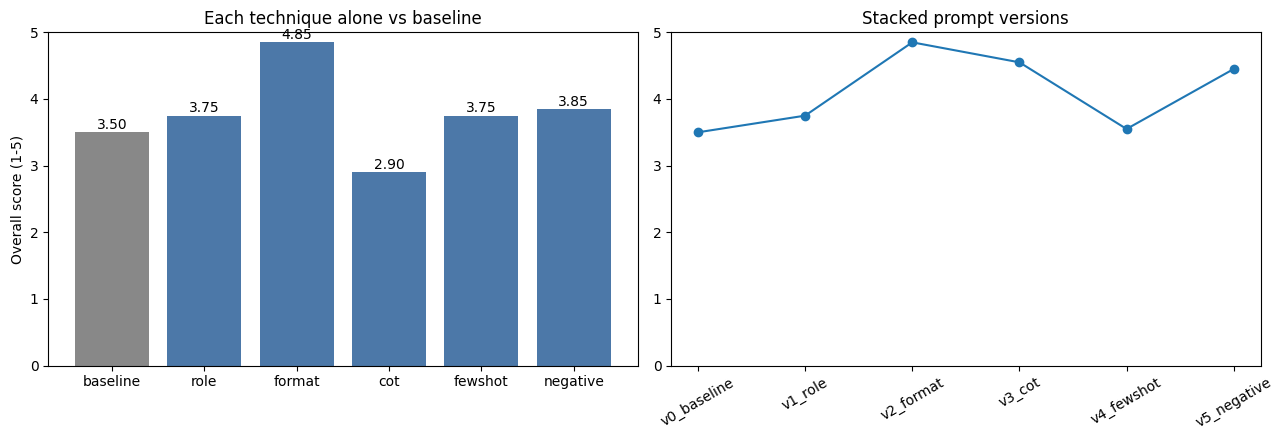

In [9]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
labels = ["baseline"] + list(ISO.keys())
vals = [RESULTS["v0_baseline"]["avg"]] + [ISO[t]["avg"] for t in ISO]
ax[0].bar(labels, vals, color=["#888"] + ["#4C78A8"] * len(ISO))
ax[0].set_title("Each technique alone vs baseline"); ax[0].set_ylabel("Overall score (1-5)"); ax[0].set_ylim(0, 5)
for x, v in zip(labels, vals): ax[0].text(x, v + 0.05, f"{v:.2f}", ha="center")

names = list(PROMPT_VERSIONS.keys())
ax[1].plot(names, [PROMPT_VERSIONS[n]["score"] for n in names], marker="o")
ax[1].set_title("Stacked prompt versions"); ax[1].set_ylim(0, 5); ax[1].tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.savefig("day19_score_comparison.png", dpi=150); plt.show()

json.dump({"versions": PROMPT_VERSIONS,
           "isolated": {t: {"acc": ISO[t]["avg_acc"], "fmt": ISO[t]["avg_fmt"], "overall": ISO[t]["avg"]} for t in ISO},
           "baseline": {k: RESULTS["v0_baseline"][k] for k in ("avg_acc", "avg_fmt", "avg")}},
          open("day19_results.json", "w"), indent=2)

## Step 8: Which single technique gave the largest improvement?

In [10]:
base = RESULTS["v0_baseline"]["avg"]
gains = {t: ISO[t]["avg"] - base for t in ISO}
for t, g in sorted(gains.items(), key=lambda x: -x[1]):
    print(f"{t:10s} {g:+.2f}  (acc {ISO[t]['avg_acc'] - RESULTS['v0_baseline']['avg_acc']:+.2f}, fmt {ISO[t]['avg_fmt'] - RESULTS['v0_baseline']['avg_fmt']:+.2f})")
best = max(gains, key=gains.get)
print("\nBest single technique:", best)

format     +1.35  (acc +0.20, fmt +2.50)
negative   +0.35  (acc +0.20, fmt +0.50)
role       +0.25  (acc +0.40, fmt +0.10)
fewshot    +0.25  (acc +0.20, fmt +0.30)
cot        -0.60  (acc +0.20, fmt -1.40)

Best single technique: format


### Best technique analysis
- **Winner (overall score):** `format specification`, with a gain of **+1.35** over the baseline (3.50 -> 4.85).
- **Where the gain came from:** +2.50 on format consistency but only +0.20 on accuracy. The rubric rewards the `Answer:` format, so part of this win is by design. By accuracy alone, **role assignment** helped most (+0.40), but that is a single question (input 2, the Pro-vs-Basic price difference): the baseline gave a long step-by-step answer that scored 1, and one input moves the 10-input average by 0.4.
- **Hypothesis:** the baseline model already answered 9/10 questions correctly (accuracy 4.60), so there was little accuracy left to gain. What it lacked was *control over the shape of its output*: it mixed one-liners, multi-sentence explanations and step-by-step lists. A small 1.5B model follows a concrete output template reliably, which removes the freedom to ramble, and rambling is also what produced the one wrong baseline score.
- **Why chain-of-thought hurt (-0.60 alone):** accuracy rose slightly (+0.20) but format fell by 1.40, because the model wrote long reasoning with no `Answer:` line. For extraction-style QA over a short context, extra reasoning added length, not correctness.
- **Why stacking few-shot dropped the score (4.55 -> 3.55):** not diagnosed in this run. A plausible, untested explanation is that the longer prompt (two examples plus CoT) pushed outputs past the token limit or made the model imitate the example style instead of writing the `Answer:` line. Checking `RESULTS['v4_fewshot']` output-by-output would confirm it.
- **Caveats:** only 10 inputs, an automatic keyword scorer, greedy decoding on one small model. Differences of 0.2 are a single question and should not be over-read.

## Step 9: Grounding system prompt for the RAG assistant
It tells the model to answer **only** from the context and to use a **fixed refusal sentence** otherwise. A fixed sentence matters because our code can detect it exactly, so "refused" vs "answered from training data" is a simple string check.

In [11]:
REFUSAL = "I cannot answer this from the provided context."
GROUNDING_PROMPT = f'''You are the Veridia Labs support assistant.
Answer ONLY using the Context provided by the user.
If the Context does not directly contain the information needed to answer, reply with exactly: "{REFUSAL}"
Never use your own background knowledge, even if you know the answer. Never guess.
Keep answers to one short sentence.'''

def grounded_answer(q):
    ctx = retrieve(q)
    return chat([{"role": "system", "content": GROUNDING_PROMPT},
                 {"role": "user", "content": f"Context:\n{ctx}\n\nQuestion: {q}"}])

def ungrounded_answer(q):
    ctx = retrieve(q)
    return chat(build_messages({}, ctx, q))

OUT_OF_CONTEXT = [
    "What is the capital of Australia?",
    "Who wrote the novel 1984?",
    "What is the boiling point of water at sea level in Celsius?",
    "Who is the CEO of Google?",
    "What was Veridia Labs' annual revenue last year?",   # sounds related but is NOT in the KB
]

def refused(out): return "cannot answer" in out.lower()

print("=== WITH grounding prompt ===")
ok = 0
for q in OUT_OF_CONTEXT:
    out = grounded_answer(q)
    verdict = "REFUSED correctly" if refused(out) else "ANSWERED from training data anyway"
    ok += refused(out)
    print(f"- {q}\n    {verdict} | {out[:120]!r}")
print(f"\nCorrect refusals: {ok}/5")

print("\n=== WITHOUT grounding (baseline prompt) for contrast ===")
ok0 = 0
for q in OUT_OF_CONTEXT:
    out = ungrounded_answer(q)
    ok0 += refused(out)
    print(f"- {q}\n    {'REFUSED' if refused(out) else 'ANSWERED from training data'} | {out[:120]!r}")
print(f"\nRefusals without grounding: {ok0}/5")

=== WITH grounding prompt ===
- What is the capital of Australia?
    REFUSED correctly | 'I cannot answer this from the provided context.'
- Who wrote the novel 1984?
    REFUSED correctly | 'I cannot answer this from the provided context.'
- What is the boiling point of water at sea level in Celsius?
    ANSWERED from training data anyway | 'The boiling point of water at sea level is 100 degrees Celsius.'
- Who is the CEO of Google?
    REFUSED correctly | 'I cannot answer this from the provided context.'
- What was Veridia Labs' annual revenue last year?
    ANSWERED from training data anyway | "The provided context does not include any information about Veridia Labs' annual revenue."

Correct refusals: 3/5

=== WITHOUT grounding (baseline prompt) for contrast ===
- What is the capital of Australia?
    ANSWERED from training data | 'The capital of Australia is Canberra.'
- Who wrote the novel 1984?
    ANSWERED from training data | 'The context does not provide information about wh

### Sanity check: does grounding over-refuse?
A prompt that refuses everything would score 5/5 above but be useless. Two in-context questions should still be answered.

In [12]:
for item in EVAL[:2]:
    out = grounded_answer(item["q"])
    print(item["q"], "->", out, "| refused?", refused(out))

Who founded Veridia Labs and in which city? -> Veridia Labs was founded in 2019 in Pune, India by Dr. Meera Kulkarni. | refused? False
When was Lumen launched? -> Lumen was launched in March 2021. | refused? False


## Step 9b: Hardened grounding prompt (v2) and a similarity gate
v1 let one general-knowledge question through (the model knew the answer too well). Two fixes:
1. **Prompt v2:** an explicit rule that general knowledge is NOT answerable, plus one refusal example.
2. **Similarity gate:** if the best retrieved chunk is not similar enough to the question, refuse in code and never call the model. This is the same idea as a relevance threshold in RAG.

We also report two refusal checks: **strict** (exact refusal sentence = instruction following) and **lenient** (refusal in any wording = actual safety).

In [13]:
def refused_lenient(out):
    o = out.lower()
    return any(p in o for p in ["cannot answer", "does not provide", "does not include",
                                "does not contain", "no information", "not mentioned"])

GROUNDING_V2 = GROUNDING_PROMPT + '''
Before answering, check: does a sentence in the Context state this? If not, reply with the exact refusal sentence.
General-knowledge questions (science, geography, famous people) are NOT answerable, even if you know the answer.

Example:
Context: - Orbit Cafe opens at 8am.
Question: What is the capital of France?
Reply: ''' + REFUSAL

def grounded_v2(q):
    return chat([{"role": "system", "content": GROUNDING_V2},
                 {"role": "user", "content": f"Context:\n{retrieve(q)}\n\nQuestion: {q}"}])

V2_OUT = {}
for q in OUT_OF_CONTEXT:
    V2_OUT[q] = grounded_v2(q)
    print(f"strict={refused(V2_OUT[q])} lenient={refused_lenient(V2_OUT[q])} | {q}\n    {V2_OUT[q][:110]!r}")
v2_strict = sum(refused(o) for o in V2_OUT.values())
print(f"\nGrounding v2 strict refusals: {v2_strict}/5")

strict=True lenient=True | What is the capital of Australia?
    'I cannot answer this from the provided context.'
strict=True lenient=True | Who wrote the novel 1984?
    'I cannot answer this from the provided context.'
strict=True lenient=True | What is the boiling point of water at sea level in Celsius?
    'I cannot answer this from the provided context.'
strict=True lenient=True | Who is the CEO of Google?
    'I cannot answer this from the provided context.'
strict=True lenient=True | What was Veridia Labs' annual revenue last year?
    'I cannot answer this from the provided context.'

Grounding v2 strict refusals: 5/5


In [14]:
def top_score(q):
    return float((kb_vecs @ embedder.encode([q], normalize_embeddings=True)[0]).max())

in_scores  = [round(top_score(i["q"]), 2) for i in EVAL]
out_scores = [round(top_score(q), 2) for q in OUT_OF_CONTEXT]
print("IN-CONTEXT :", in_scores)
print("OUT-OF-CTX :", out_scores)
print("min in-context =", min(in_scores), "| max out-of-context that is clearly unrelated =", sorted(out_scores)[-2])
print("NOTE: the Veridia revenue question scores high because it mentions Veridia; the gate cannot catch it, the prompt must.")

IN-CONTEXT : [0.86, 0.63, 0.65, 0.7, 0.72, 0.81, 0.7, 0.76, 0.57, 0.63]
OUT-OF-CTX : [0.08, 0.13, 0.22, 0.24, 0.64]
min in-context = 0.57 | max out-of-context that is clearly unrelated = 0.24
NOTE: the Veridia revenue question scores high because it mentions Veridia; the gate cannot catch it, the prompt must.


In [15]:
GATE = 0.35

def grounded_final(q):
    if top_score(q) < GATE:
        return REFUSAL          # gate: refuse in code, skip the model
    return grounded_v2(q)

print("IN-CONTEXT (should be answered):")
over = 0
for item in EVAL:
    out = grounded_final(item["q"])
    over += refused(out)
    print(f"  refused={refused(out)} | {item['q']}\n      {out[:90]!r}")
print(f"Wrongly refused: {over}/10\n")

print("OUT-OF-CONTEXT (should be refused):")
gated = sum(top_score(q) < GATE for q in OUT_OF_CONTEXT)
final_ok = 0
for q in OUT_OF_CONTEXT:
    out = grounded_final(q)
    final_ok += refused(out)
    print(f"  gate_blocked={top_score(q) < GATE} refused={refused(out)} | {q}")
print(f"Correctly refused: {final_ok}/5  (gate alone caught {gated}/5, prompt caught the rest)")

IN-CONTEXT (should be answered):
  refused=False | Who founded Veridia Labs and in which city?
      'Dr. Meera Kulkarni founded Veridia Labs in Pune, India.'
  refused=False | When was Lumen launched?
      'Lumen was launched in March 2021.'
  refused=False | How much more per month does Pro cost than Basic?
      'The Pro plan costs $70 more per month than the Basic plan.'
  refused=False | Can I get a refund on an annual plan 20 days after buying it?
      'No, you cannot get a refund on an annual plan 20 days after purchasing it.'
  refused=False | When is customer support available?
      'Customer support is available from 9am to 6pm IST, Monday to Friday, at support@veridia.ex'
  refused=False | How many employees does Veridia Labs have in total?
      'Veridia Labs has 240 employees in total.'
  refused=False | Which file types does Lumen support?
      'Lumen supports PDF, DOCX, and CSV files up to 50 MB each.'
  refused=False | Where is customer data stored and how is it enc

In [16]:
# Final summary: copy these numbers into the Step 10 write-up
base = RESULTS["v0_baseline"]
print("Baseline overall:", round(base["avg"], 2), "| accuracy", round(base["avg_acc"], 2), "| format", round(base["avg_fmt"], 2))
best_stack = max(PROMPT_VERSIONS, key=lambda k: PROMPT_VERSIONS[k]["score"])
print("Best stacked version:", best_stack, PROMPT_VERSIONS[best_stack]["score"])
print("Best single technique (overall):", best)
print("Grounding v1 strict:", sum(refused(grounded_answer(q)) for q in OUT_OF_CONTEXT), "/5")
print("Grounding v2 strict:", v2_strict, "/5 | final system (gate + v2):", final_ok, "/5 | wrongly refused:", over, "/10")
json.dump({"grounding": {"v2_strict": v2_strict, "final_ok": final_ok, "over_refused": over,
                          "gate": GATE, "in_scores": in_scores, "out_scores": out_scores}},
          open("day19_grounding.json", "w"), indent=2)

Baseline overall: 3.5 | accuracy 4.6 | format 2.4
Best stacked version: v2_format 4.85
Best single technique (overall): format
Grounding v1 strict: 3 /5
Grounding v2 strict: 5 /5 | final system (gate + v2): 5 /5 | wrongly refused: 0 /10


## Step 10: Write-up

**Baseline score:** 3.50 (accuracy 4.60, format 2.40) | **Best stacked version:** `v2_format` (score 4.85)

**Per-technique results (each alone vs baseline 3.50):** format 4.85, negative constraints 3.85, role 3.75, few-shot 3.75, chain-of-thought 2.90. Stacked versions: v0 3.50 -> v1 3.75 -> v2 4.85 -> v3 4.55 -> v4 3.55 -> v5 4.45. See `day19_score_comparison.png`.

**Best technique and hypothesis:** format specification (+1.35). Mostly a format-consistency gain; accuracy was already high. Details in the analysis above.

**Grounding prompt results:**
| System | Strict (exact refusal sentence) | Lenient (refused in any wording) |
|---|---|---|
| No grounding (baseline prompt) | 0/5 | 3/5 |
| Grounding v1 | 3/5 | 4/5 |
| Grounding v2 (hardened prompt) | 5/5 | 5/5 |
| Final system: similarity gate (0.35) + v2 | 5/5 | 5/5 |

- v1 failure: the boiling-point question was answered from training data. The revenue question was refused in different words, which the strict check missed.
- Similarity scores: in-context questions 0.57-0.86; unrelated out-of-context questions 0.08-0.24, so a 0.35 gate separates them. The Veridia revenue question scores 0.64 (it mentions Veridia), so the gate cannot catch it and the prompt must.
- Over-refusal check: **0/10** valid questions were wrongly refused.

**Limitation found:** refusal rate is not correctness. Under the final system, the refund question ("annual plan, 20 days after buying") was answered **"No"**, but the context says annual plans are refundable within 30 days, so the correct answer is Yes. The other 9 in-context answers were correct. The stricter grounding prompt appears to have cost the small model some reasoning on a question that needs a comparison (20 < 30). Next step: add a correctness check to the over-refusal test.

**Key lesson:** prompts are experiments: change one thing, measure on the same inputs, keep a version log, and test the opposite failure too (a prompt that refuses correctly must still answer correctly).